# Nhận diện Mũ Bảo Hộ (Hard Hat Detection) với YOLO11

## 1. Kiểm tra môi trường và phần cứng (GPU/CPU)

In [1]:
%pip install -U ultralytics
from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 43.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Mounted at /content/drive


In [2]:
!git clone https://github.com/baocodeai/hard-hat-detection.git
%cd /content/hard-hat-detection

Cloning into 'hard-hat-detection'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 9 (delta 0), reused 9 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 16.92 MiB | 12.47 MiB/s, done.
/content/hard-hat-detection


In [11]:
!mkdir -p datasets
!unzip -q "/content/drive/MyDrive/Learn/Hard-hat-detection/hard-hat.zip" -d ./datasets/

In [4]:
import torch
import ultralytics
from ultralytics import YOLO

ultralytics.checks()
print(f'CUDA available: {torch.cuda.is_available()}')

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.2/112.6 GB disk)
CUDA available: True


## 2. Kiểm tra cấu trúc dữ liệu và tệp `data.yaml`

In [6]:
! pwd

/content/hard-hat-detection


In [12]:
from pathlib import Path
import yaml

data_yaml_path = Path('./datasets/hard-hat/data.yaml')
assert data_yaml_path.exists(), f'Không tìm thấy {data_yaml_path}. Hãy kiểm tra lại thư mục datasets!'

with open(data_yaml_path, 'r', encoding='utf-8') as f:
    data_cfg = yaml.safe_load(f)

print('Cấu hình dataset hiện tại:', data_cfg)

Cấu hình dataset hiện tại: {'path': 'datasets/hard-hat', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 1, 'names': ['head'], 'roboflow': {'workspace': 'joseph-nelson', 'project': 'hard-hat-workers', 'version': 14, 'license': 'Public Domain', 'url': 'https://universe.roboflow.com/joseph-nelson/hard-hat-workers/dataset/14'}}


## 3. Huấn luyện mô hình (Train)

In [17]:
import shutil

model = YOLO('yolo11s.pt')
results = model.train(
    data=str(data_yaml_path),
    epochs=50,
    imgsz=640,
    batch=32,
    project='runs/detect',
    name='train_exp',
    exist_ok=True
)

# Lưu trọng số tốt nhất vào thư mục models/
Path('models').mkdir(exist_ok=True)
best_pt = Path('runs/detect/train_exp/weights/best.pt')
if best_pt.exists():
    shutil.copy(best_pt, 'models/best.pt')
    print('Đã lưu mô hình tốt nhất tại: models/best.pt')

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets/hard-hat/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_exp, nbs=64, nms=None, opset=None, optimize=False, optim

## 4. Đánh giá mô hình (Evaluate trên tập Test)

In [18]:
import shutil
from pathlib import Path

Path('models').mkdir(exist_ok=True)
shutil.copy('runs/detect/runs/detect/train_exp/weights/best.pt', 'models/best.pt')
print("Đã sao chép thành công: models/best.pt")

Đã sao chép thành công: models/best.pt


In [34]:
best_model = YOLO('models/best.pt')
metrics = best_model.val(
    data='datasets/hard-hat/data.yaml',
    split='test',
    imgsz=640,
    conf=0.5,
    plots=True,
    name='val_exp',
    exist_ok=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1034.0±459.0 MB/s, size: 30.7 KB)
val: Scanning /content/hard-hat-detection/datasets/hard-hat/test/labels.cache... 706 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 706/706 211.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 4.2it/s 10.7s
                   all        706       2641      0.966      0.943       0.94      0.664
Speed: 1.1ms preprocess, 6.3ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/hard-hat-detection/runs/detect/val_exp


In [36]:
print(f"\nmAP@50:    {metrics.box.map50:.4f}")
print(f"mAP@50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")


mAP@50:    0.9402
mAP@50-95: 0.6643
Precision: 0.9663
Recall:    0.9432


## 5. Trực quan hóa biểu đồ huấn luyện & Ma trận nhầm lẫn

In [42]:
best_model = YOLO("models/best.pt")
best_model.predict(
    source="datasets/hard-hat/test/images",
    conf=0.4,
    save=True,
    name="predict_exp_09",
    exist_ok=True
)


image 1/706 /content/hard-hat-detection/datasets/hard-hat/test/images/005298_jpg.rf.d6fe5e5635be9509610a059a66e432d5.jpg: 448x640 8 heads, 30.7ms
image 2/706 /content/hard-hat-detection/datasets/hard-hat/test/images/005299_jpg.rf.fb7c522d8fc48969a295a287032b53c1.jpg: 448x640 1 head, 60.4ms
image 3/706 /content/hard-hat-detection/datasets/hard-hat/test/images/005300_jpg.rf.75d17868202e675bdb300b60b8cb2722.jpg: 480x640 1 head, 66.8ms
image 4/706 /content/hard-hat-detection/datasets/hard-hat/test/images/005301_jpg.rf.e9c1d355a0bb57e4e8d81a36a39042c8.jpg: 480x640 5 heads, 151.5ms
image 5/706 /content/hard-hat-detection/datasets/hard-hat/test/images/005302_jpg.rf.276a11259090a88e935e5982c991757b.jpg: 640x512 1 head, 108.5ms
image 6/706 /content/hard-hat-detection/datasets/hard-hat/test/images/005303_jpg.rf.cce32679b8fede85699505a2f2624366.jpg: 480x640 5 heads, 136.2ms
image 7/706 /content/hard-hat-detection/datasets/hard-hat/test/images/005304_jpg.rf.86144453ee26db5dc0473f126bfcfeae.jpg: 6

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'head'}
 obb: None
 orig_img: array([[[ 97, 116,  97],
         [105, 124, 105],
         [107, 127, 108],
         ...,
         [ 80,  98,  91],
         [ 74,  92,  85],
         [ 74,  92,  85]],
 
        [[102, 121, 102],
         [107, 126, 107],
         [106, 126, 107],
         ...,
         [ 79,  97,  90],
         [ 74,  92,  85],
         [ 74,  92,  85]],
 
        [[110, 129, 110],
         [112, 131, 112],
         [108, 128, 109],
         ...,
         [ 79,  97,  90],
         [ 74,  92,  85],
         [ 75,  93,  86]],
 
        ...,
 
        [[223, 239, 215],
         [225, 241, 217],
         [226, 242, 218],
         ...,
         [159, 196, 194],
         [132, 169, 167],
         [159, 196, 194]],
 
        [[222, 238, 214],
         [223, 239, 215],
         [224, 240, 216],
       

Đang hiển thị: runs/detect/runs/detect/train_exp/results.png


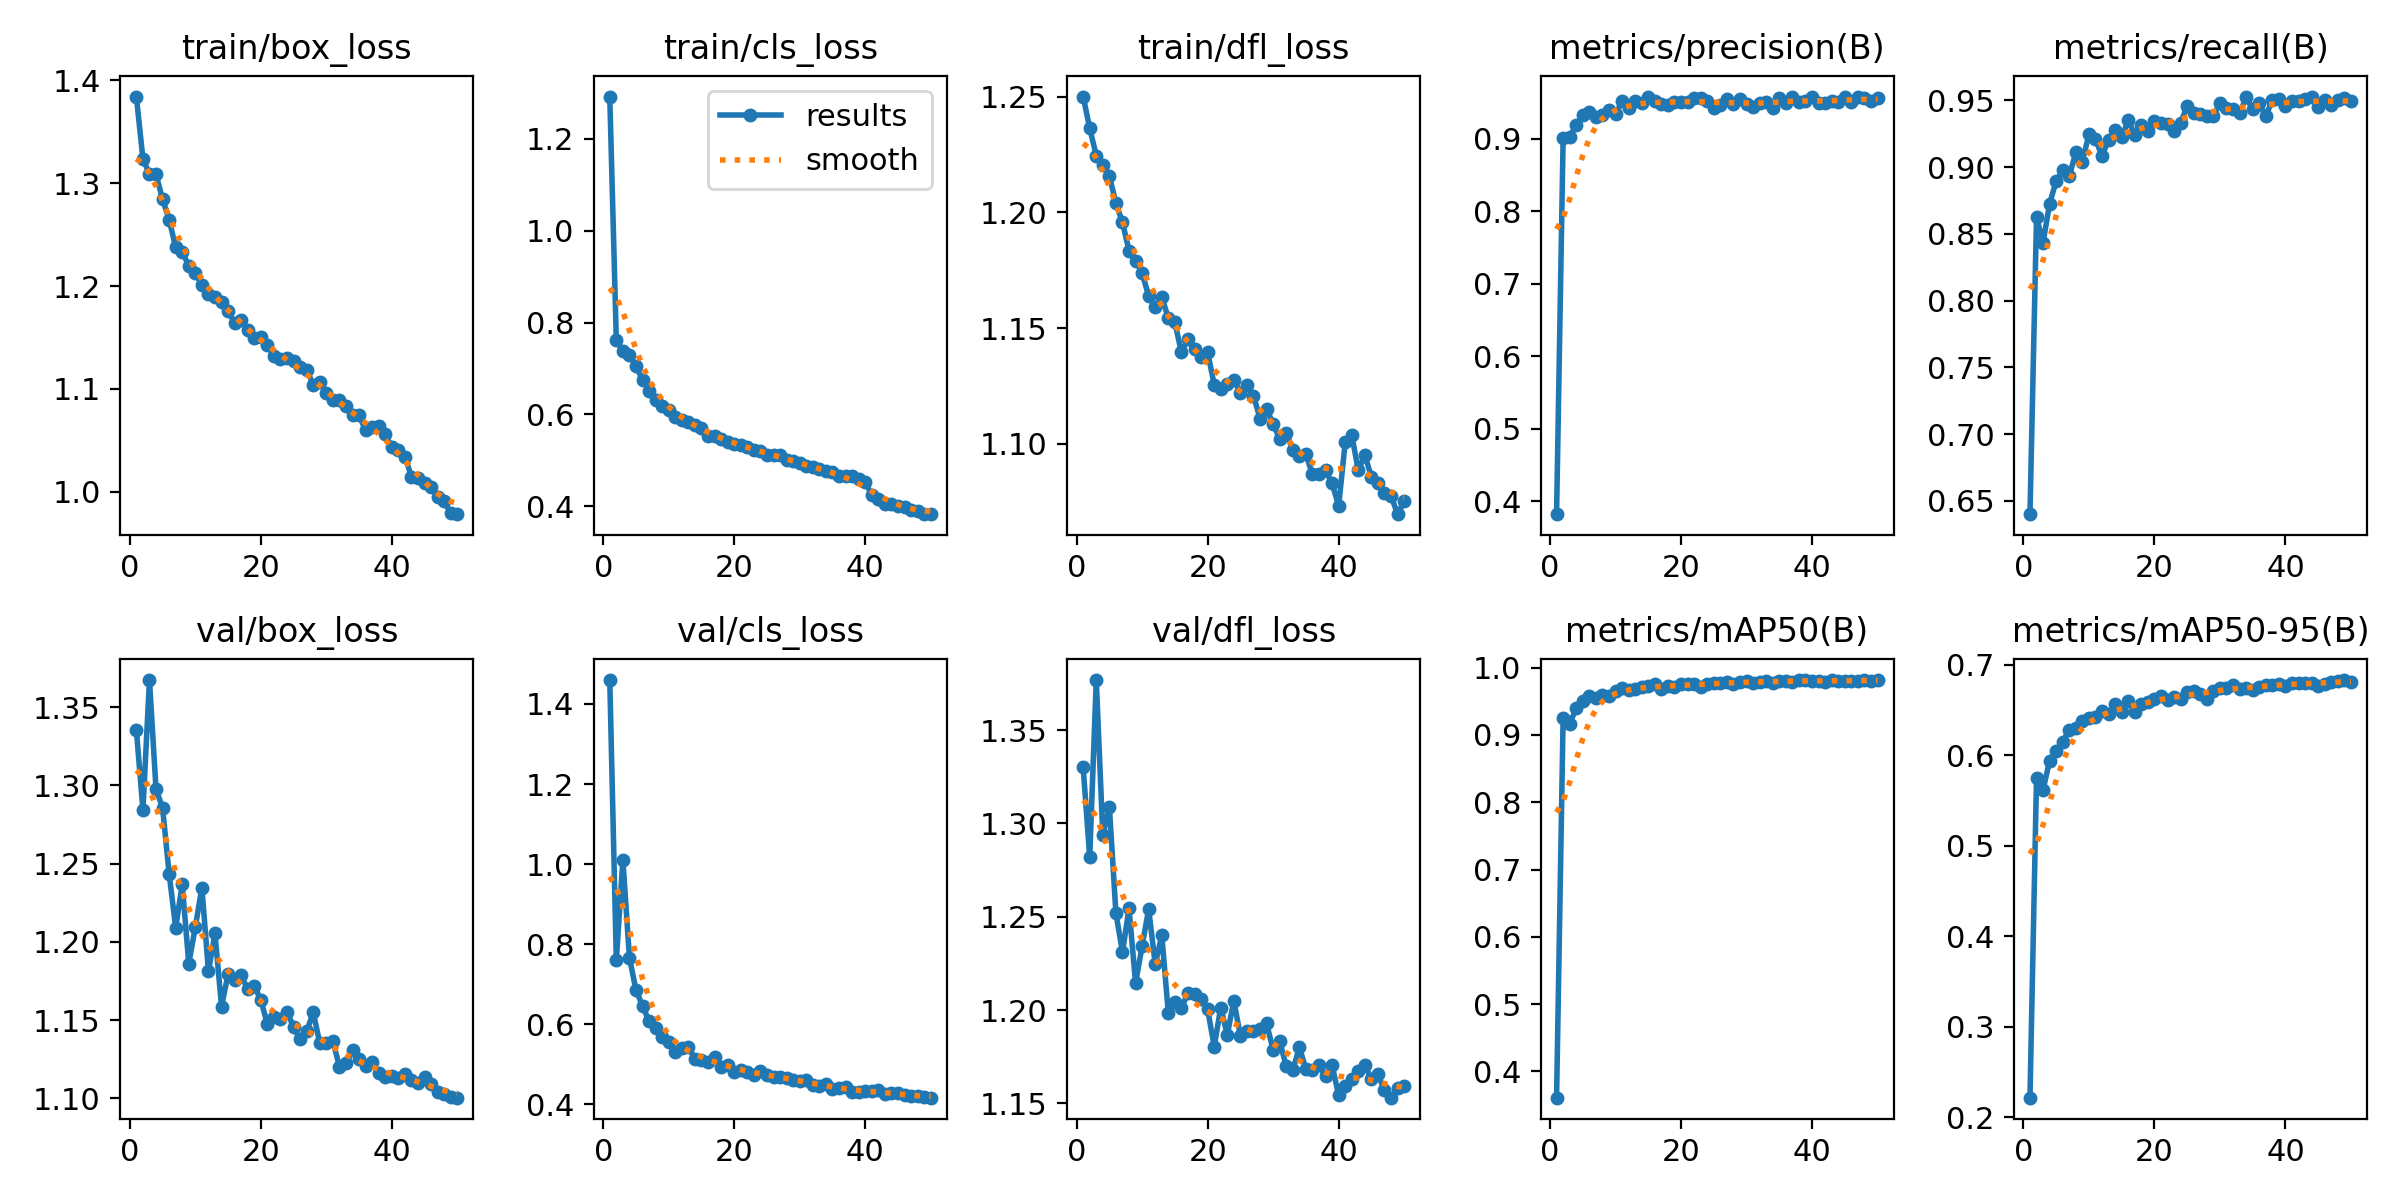

Đang hiển thị: runs/detect/val_exp/confusion_matrix.png


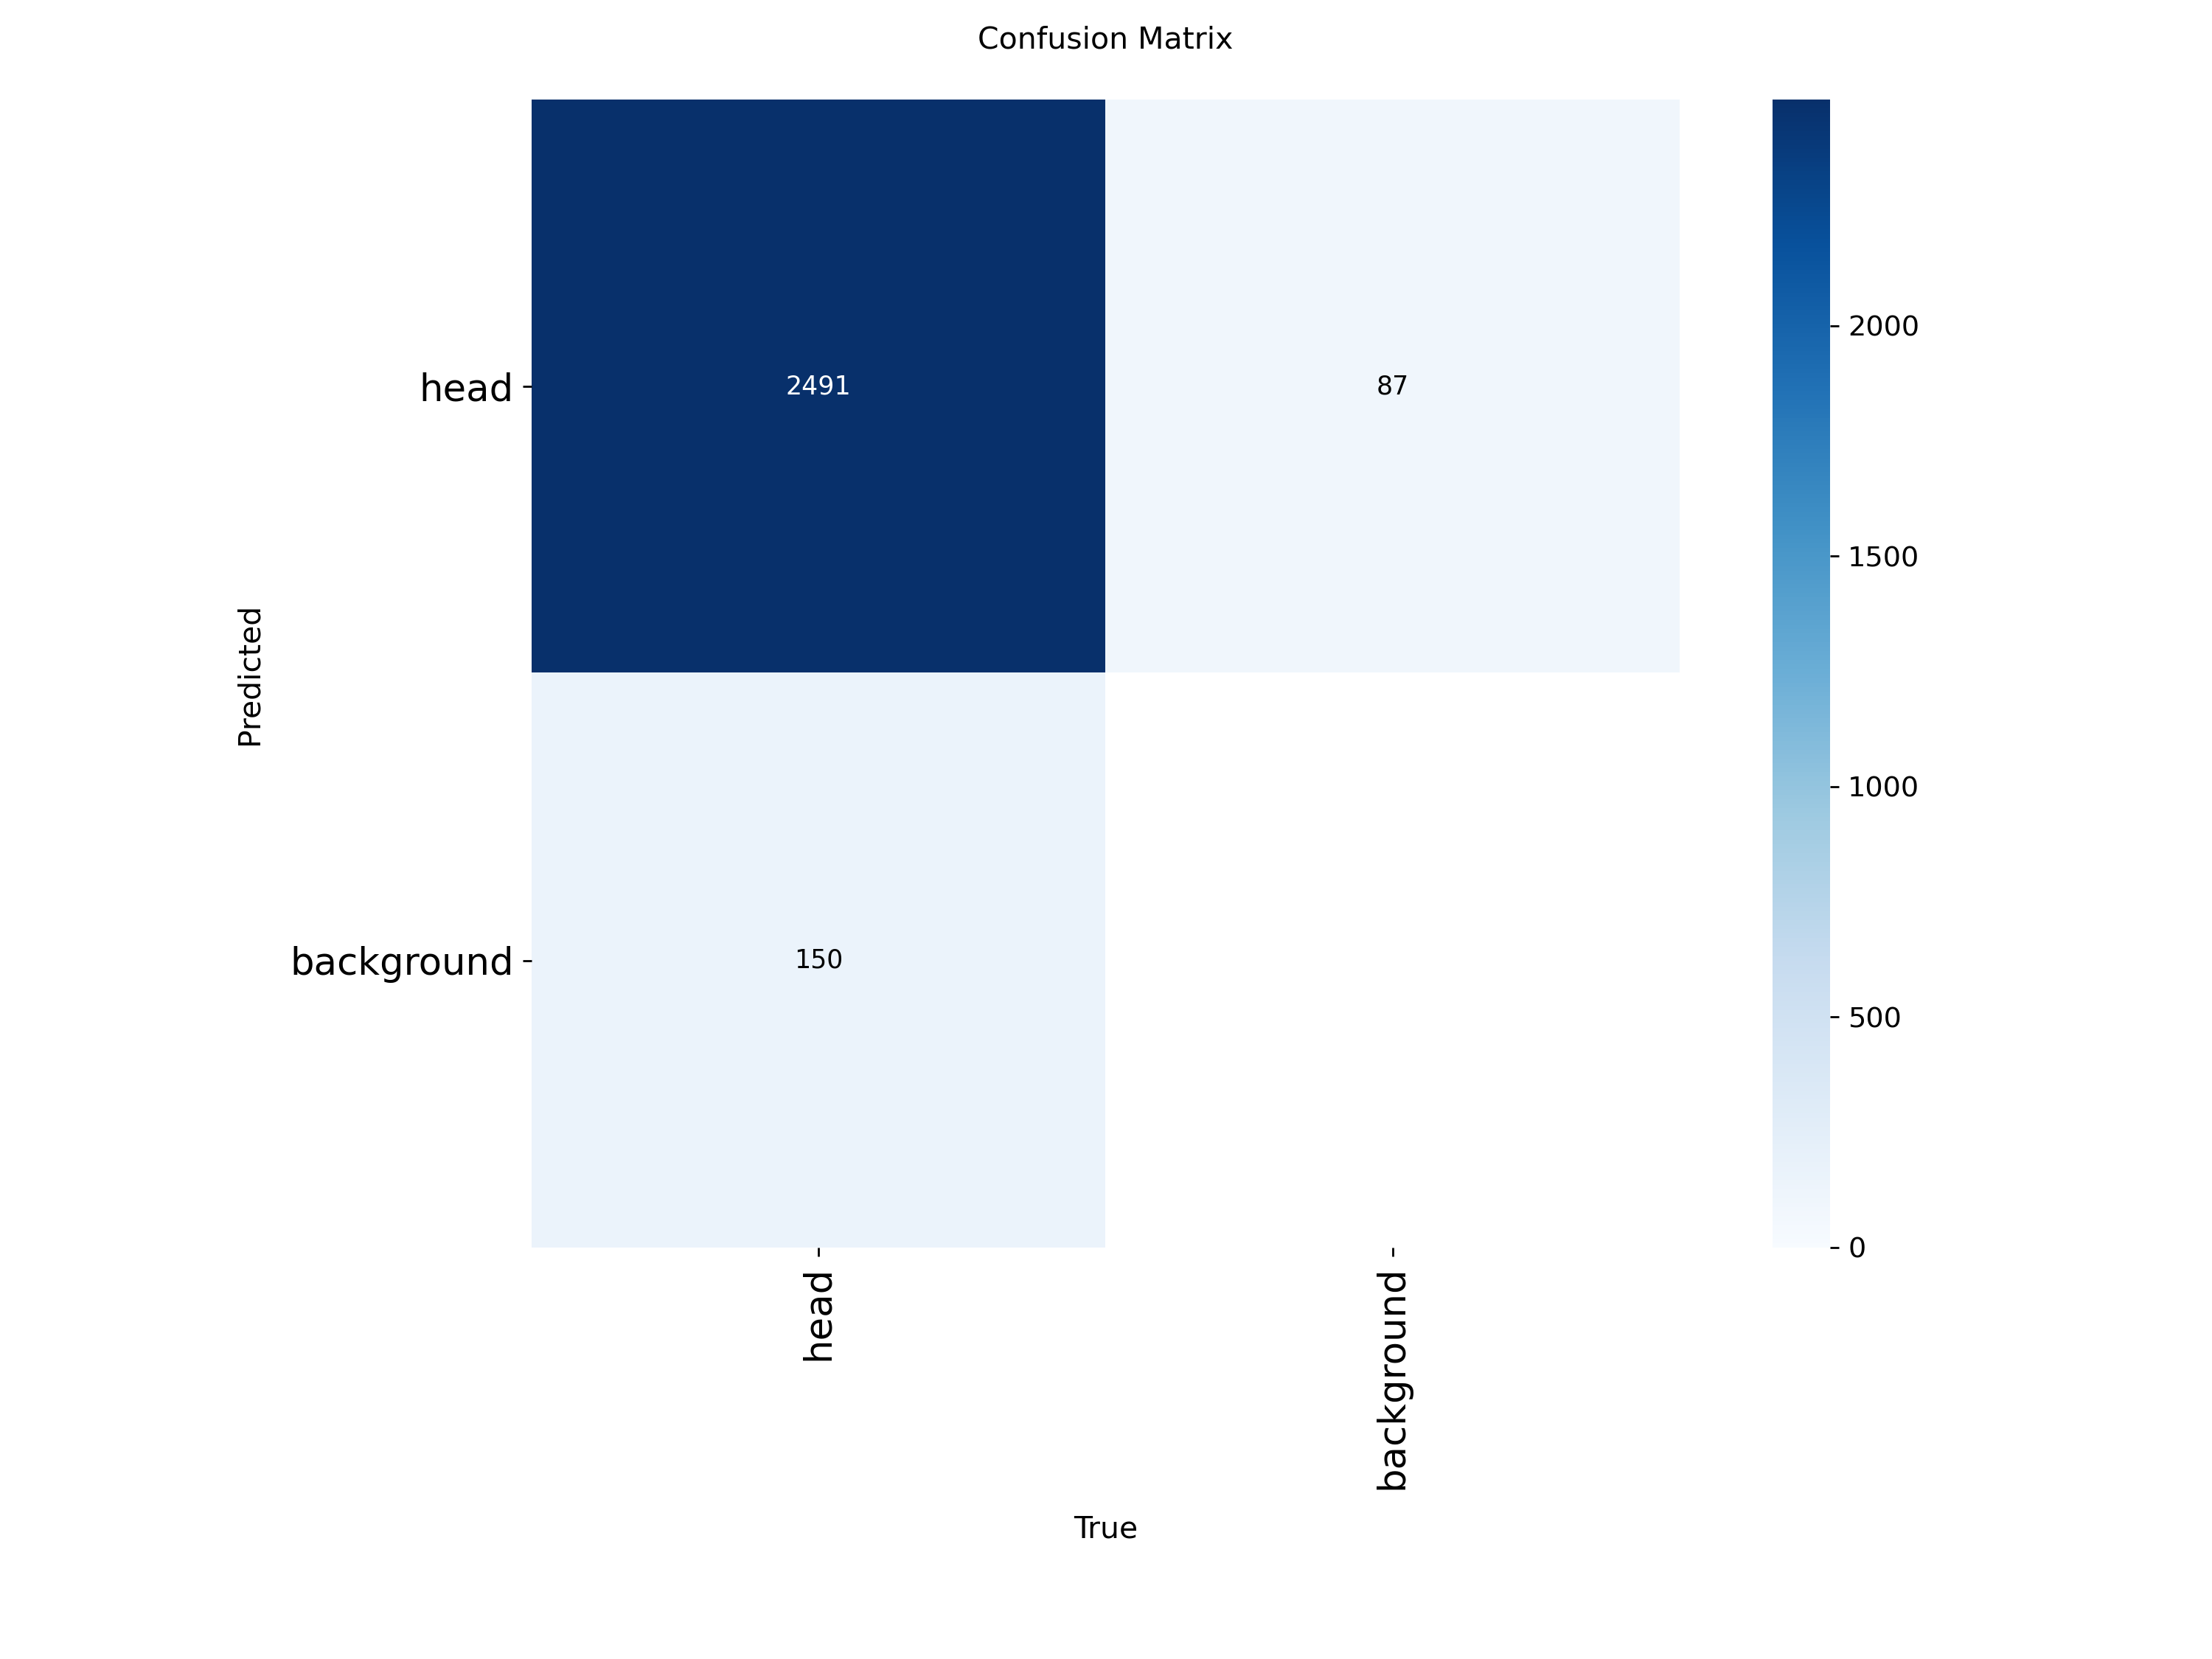

In [43]:
# 2. Hiển thị biểu đồ huấn luyện (results.png) và ma trận nhầm lẫn (confusion_matrix.png)
for plot_name, w in [("results.png", 800), ("confusion_matrix.png", 650)]:
    found = list(Path("runs").rglob(plot_name))
    if found:
        print(f"Đang hiển thị: {found[0]}")
        display(Image(filename=str(found[0]), width=w))

## 6. Chạy nhận diện thử nghiệm (Predict) và hiển thị kết quả

Tìm thấy 3 ảnh dự đoán (conf >= 0.7):


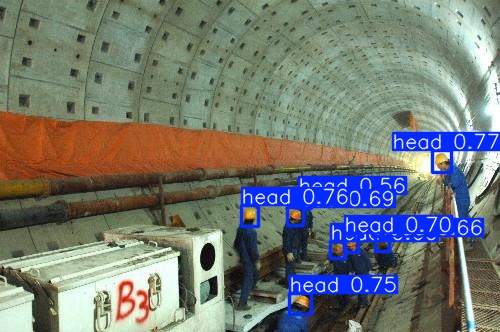

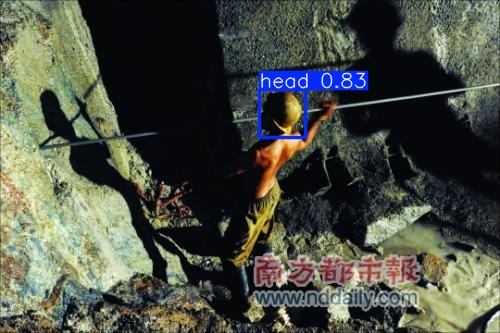

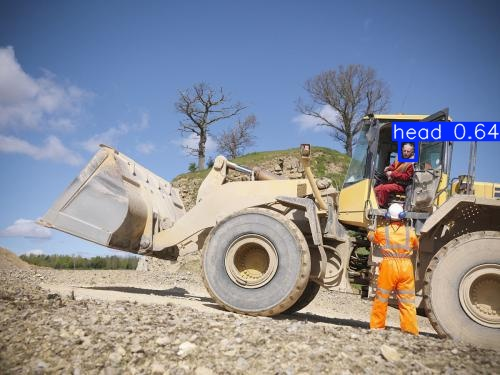

In [45]:
# 3. Lấy và hiển thị 3 ảnh nhận diện mẫu mới từ thư mục predict_exp_07
pred_images = sorted(
    p for p in Path("runs").rglob("predict_exp_09/*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)[:3]

print(f"Tìm thấy {len(pred_images)} ảnh dự đoán (conf >= 0.7):")
for img_path in pred_images:
    display(Image(filename=str(img_path), width=600))

In [46]:
import shutil
from pathlib import Path

out_dir = Path("/content/drive/MyDrive/Learn/Hard_hat_detection/output")
out_dir.mkdir(parents=True, exist_ok=True)

for filename in ["best.pt", "results.png", "confusion_matrix.png"]:
    matches = list(Path("runs").rglob(filename))
    if matches:
        shutil.copy(matches[0], out_dir / filename)
        print(f"Đã lưu: {matches[0]} -> {out_dir / filename}")
    else:
        print(f"Không tìm thấy tệp: {filename}")

Đã lưu: runs/detect/runs/detect/train_exp/weights/best.pt -> /content/drive/MyDrive/Learn/Hard_hat_detection/output/best.pt
Đã lưu: runs/detect/runs/detect/train_exp/results.png -> /content/drive/MyDrive/Learn/Hard_hat_detection/output/results.png
Đã lưu: runs/detect/val_exp/confusion_matrix.png -> /content/drive/MyDrive/Learn/Hard_hat_detection/output/confusion_matrix.png


In [47]:
from google.colab import files
files.download('models/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>